# Лабораторная №2

Морфология, части речи, синтаксические пары и анафора в Ubuntu Dialogue Corpus.

## Подготовка

In [ ]:
from __future__ import annotations

import hashlib
import html
import json
import math
import re
from collections import Counter, defaultdict, deque
from pathlib import Path

import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from spacy import displacy

ROOT = Path.cwd().resolve()
if not (ROOT / 'lab2.py').exists():
    ROOT = ROOT / 'text-analyse' / 'lab2'
OUT = ROOT / 'results'
MODEL = 'en_core_web_sm'
SLANG = {'im', 'dont', 'doesnt', 'cant', 'u', 'ur', 'lol', 'sudo', 'apt', 'ubuntu', 'thx', 'plz', 'gonna', 'wanna'}
GENDER = {'man': 'Masc', 'father': 'Masc', 'brother': 'Masc', 'boy': 'Masc',
          'woman': 'Fem', 'mother': 'Fem', 'sister': 'Fem', 'girl': 'Fem'}
HUMAN = set(GENDER) | {'user', 'person', 'people', 'developer', 'admin', 'friend', 'guy', 'someone'}
PRONOUNS = {'he': ('Sing', 'Masc'), 'him': ('Sing', 'Masc'),
            'she': ('Sing', 'Fem'), 'her': ('Sing', 'Fem'),
            'it': ('Sing', 'Neut'), 'they': ('Plur', None), 'them': ('Plur', None)}


from IPython.display import display, Image, Markdown


### Подготовка текста

In [2]:
def prepare_text(text: str) -> str:
    """Сохраняем регистр, сленг и синтаксис."""
    text = html.unescape(text)
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\u200b\ufeff]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

### Извлечение пар «субъект — действие»

In [3]:
def extract_pairs(doc):
    """Извлекаем грамматический субъект и глагол."""
    result = []
    for verb in doc:
        if verb.pos_ != 'VERB':
            continue

        subjects = [c for c in verb.children if c.dep_ in {'nsubj', 'nsubjpass'}]
        # У однородных глаголов субъект может быть общим.
        if not subjects and verb.dep_ == 'conj' and verb.head.pos_ == 'VERB':
            subjects = [c for c in verb.head.children if c.dep_ in {'nsubj', 'nsubjpass'}]

        for subject in subjects:
            coordinated = [subject] + [c for c in subject.conjuncts if c.pos_ in {'NOUN', 'PROPN', 'PRON'}]
            action = ('not ' if any(c.dep_ == 'neg' for c in verb.children) else '') + verb.lemma_.lower()
            for token in coordinated:
                if token.pos_ in {'NOUN', 'PROPN', 'PRON'}:
                    result.append((token.lemma_.lower(), action, subject.dep_ == 'nsubjpass'))
    return result

### Расстояние по дереву

In [4]:
def dependency_distance(a, b) -> int:
    """Число рёбер через общего предка."""
    path = {a.i: 0}
    path.update({t.i: i for i, t in enumerate(a.ancestors, 1)})
    for distance, token in enumerate([b, *b.ancestors]):
        if token.i in path:
            return distance + path[token.i]
    return 100

### Число существительного

In [5]:
def token_number(token):
    values = token.morph.get('Number')
    return values[0] if values else None

### Род существительного

In [6]:
def token_gender(token):
    values = token.morph.get('Gender')
    return values[0] if values else GENDER.get(token.lemma_.lower())

### Разрешение местоимений

In [ ]:
def resolve_anaphora(doc, history):
    """Ищем существительное в текущей и трёх прошлых репликах."""
    decisions = []
    replacements = []

    for pronoun in doc:
        key = pronoun.lower_
        if key not in PRONOUNS or pronoun.pos_ != 'PRON':
            continue
        if pronoun.dep_ in {'poss', 'expl'}:
            continue

        head = pronoun.head
        if key == 'it' and (head.lemma_ in {'seem', 'appear'} or
                           (head.lemma_ == 'be' and any(c.dep_ in {'acomp', 'ccomp'} for c in head.children))):
            continue

        number = pronoun.morph.get('Number')
        gender = pronoun.morph.get('Gender')
        number = number[0] if number else PRONOUNS[key][0]
        gender = gender[0] if gender else PRONOUNS[key][1]
        candidates = []

        contexts = [(0, doc)] + list(enumerate(reversed(history), 1))
        for age, context in contexts:
            for noun in context:
                if noun.pos_ not in {'NOUN', 'PROPN'} or (age == 0 and noun.i >= pronoun.i):
                    continue
                noun_number = token_number(noun)
                if not noun_number or noun_number != number:
                    continue

                noun_gender = token_gender(noun)
                if gender in {'Masc', 'Fem'} and noun_gender != gender:
                    continue
                if gender == 'Neut' and (noun_gender in {'Masc', 'Fem'} or noun.lemma_.lower() in HUMAN):
                    continue

                if age == 0:
                    distance = dependency_distance(pronoun, noun)
                    recency = pronoun.i - noun.i
                else:
                    distance = len(list(pronoun.ancestors)) + len(list(noun.ancestors)) + 1
                    recency = len(context) - noun.i
                unknown_gender_penalty = 1 if gender and not noun_gender else 0
                score = distance + 6 * age + unknown_gender_penalty + .01 * recency
                candidates.append((score, age, noun.i, noun, distance, noun_gender))

        if not candidates:
            continue
        score, age, _, noun, distance, noun_gender = min(candidates, key=lambda c: (c[0], c[1], -c[2]))
        replacement = noun.text.capitalize() if pronoun.text[0].isupper() else noun.text
        replacements.append((pronoun.idx, pronoun.idx + len(pronoun), replacement))
        decisions.append(dict(pronoun=pronoun.text, antecedent=noun.text, number=number,
                              pronoun_gender=gender or 'не указан', noun_gender=noun_gender or 'не указан',
                              dependency_distance=distance, previous_utterances=age, score=round(score, 2),
                              context=noun.doc.text, original=doc.text))

    changed = doc.text
    for start, end, replacement in sorted(replacements, reverse=True):
        changed = changed[:start] + replacement + changed[end:]
    for row in decisions:
        row['changed'] = changed
    return changed, decisions

### Визуализация зависимостей

In [8]:
def draw_tree(sentence, number):
    """Рисуем дерево: родитель выше зависимого слова."""
    tokens = list(sentence)
    positions = {t.i: (i, -len(list(t.ancestors))) for i, t in enumerate(tokens)}
    depth = max(-y for _, y in positions.values())
    fig, ax = plt.subplots(figsize=(max(12, len(tokens) * .95), max(4, depth * .9 + 2)))
    for token in tokens:
        x, y = positions[token.i]
        if token.head.i != token.i and token.head.i in positions:
            hx, hy = positions[token.head.i]
            ax.annotate('', xy=(x, y + .16), xytext=(hx, hy - .16),
                        arrowprops=dict(arrowstyle='->', color='#65758A', lw=1))
            ax.text(.82 * x + .18 * hx, (y + hy) / 2, token.dep_, fontsize=9,
                    ha='center', bbox=dict(facecolor='white', edgecolor='none', pad=1))
        ax.text(x, y, f'{token.text}\n{token.pos_}', ha='center', va='center', fontsize=10,
                bbox=dict(boxstyle='round,pad=.3', facecolor='#E5EDF7', edgecolor='#3567A0'))
    ax.set(xlim=(-.8, len(tokens) - .2), ylim=(-depth - .7, .8))
    ax.axis('off')
    ax.set_title(f'{number}. {sentence.text}', fontsize=12, pad=18, wrap=True)
    fig.tight_layout()
    fig.savefig(OUT / f'tree_{number:02}.png', dpi=140, bbox_inches='tight')
    plt.close(fig)
    svg = displacy.render(sentence, style='dep', options={'compact': True, 'distance': 100}, jupyter=False)
    (OUT / f'tree_{number:02}.svg').write_text(svg, encoding='utf-8')

### Сохранение таблиц

In [9]:
def save_csv(name, rows):
    pd.DataFrame(rows).to_csv(OUT / f'{name}.csv', index=False, encoding='utf-8-sig')

### Проверки алгоритмов

In [10]:
def check_rules():
    nlp = spacy.load(MODEL, disable=['ner'])
    doc = nlp('The driver crashed and stopped.')
    pairs = extract_pairs(doc)
    assert ('driver', 'crash', False) in pairs
    assert ('driver', 'stop', False) in pairs
    assert ('driver', 'not work', False) in extract_pairs(nlp('The driver does not work.'))
    doc = nlp('The driver failed. It crashed.')
    changed, decisions = resolve_anaphora(doc, [])
    assert decisions and decisions[0]['antecedent'] == 'driver'
    assert 'Driver crashed' in changed
    assert dependency_distance(doc[1], doc[1]) == 0
    _, decisions = resolve_anaphora(nlp('They stopped.'), [nlp('The driver failed.')])
    assert not decisions
    print('Проверки правил пройдены', flush=True)

## Проверка правил
Ручные примеры: общий субъект, отрицание, замена it и согласование числа.

In [11]:
check_rules()

Проверки правил пройдены


## 1. Загрузка данных и модели

In [12]:
OUT.mkdir(exist_ok=True)
source = ROOT.parent / 'lab1/data/sample.csv.gz'
if not source.exists():
    raise FileNotFoundError('Сначала выполните lab1/prepare_data.py')
frame = pd.read_csv(source, dtype=str, keep_default_na=False)
frame['text'] = frame.text.map(prepare_text)
frame = frame.loc[frame.text.ne('')].copy()
frame['order'] = np.arange(len(frame))
frame = frame.sort_values(['group_id', 'date', 'order'], kind='stable')
frame['group'] = np.where(frame.text.str.contains('?', regex=False), 'С вопросом (?)', 'Без вопроса (?)')
nlp = spacy.load(MODEL, disable=['ner'])

In [13]:
display(frame[['group_id', 'text', 'group']].head())

,group_id,text,group
62654,10/10136.tsv,"iptables-save still doesn't help. Man, I can't...",Без вопроса (?)
62655,10/10136.tsv,there is a graphical firewall configuration pr...,Без вопроса (?)
62656,10/10136.tsv,"that program is *easy*, just drag and drop..",Без вопроса (?)
62657,10/10136.tsv,I think its fwbuilder,Без вопроса (?)
62658,10/10136.tsv,"no can do mate, need something to work without...",Без вопроса (?)


## Счётчики и контекст

In [14]:
pos = Counter()
by_group = defaultdict(Counter)
pair_counts = Counter()
pair_examples = {}
group_docs = Counter(frame.group)
audits = []
slang_seen = Counter()
anaphora = []
pronouns = Counter()
resolved = Counter()
selected_sentences = []
selected_texts = set()
example_tokens = []
current_group = None
history = deque(maxlen=3)
passive_pairs = 0
processed = 0

## POS, синтаксические пары и анафора

In [15]:
texts = ((row.text, (row.group_id, row.group, row.order)) for row in frame.itertuples(index=False))
for doc, (group_id, label, row_id) in nlp.pipe(texts, as_tuples=True, batch_size=128):
    if group_id != current_group:
        history.clear()
        current_group = group_id
    counts = Counter(t.pos_ for t in doc if not t.is_space and not t.is_punct)
    pos.update(counts)
    by_group[label].update(counts)
    if not example_tokens:
        example_tokens = [dict(token=t.text, lemma=t.lemma_, pos=t.pos_, tag=t.tag_, morph=str(t.morph), dependency=t.dep_, head=t.head.text) for t in doc]

    for subject, action, passive in extract_pairs(doc):
        pair_counts[subject, action] += 1
        passive_pairs += passive
        pair_examples.setdefault((subject, action), doc.text)

    for token in doc:
        if token.lower_ in SLANG and slang_seen[token.lower_] < 12:
            audits.append(dict(text=doc.text, token=token.text, pos=token.pos_, tag=token.tag_, dep=token.dep_, group_id=group_id, row_id=row_id))
            slang_seen[token.lower_] += 1
        if token.lower_ in PRONOUNS and token.pos_ == 'PRON':
            pronouns[token.lower_] += 1

    changed, decisions = resolve_anaphora(doc, history)
    resolved.update(r['pronoun'].lower() for r in decisions)
    if decisions and len(anaphora) < 500:
        for decision in decisions:
            if len(anaphora) < 500:
                anaphora.append(dict(group_id=group_id, row_id=row_id, **decision))

    for sent in doc.sents:
        if len(selected_sentences) >= 10:
            break
        words = [t for t in sent if t.is_alpha]
        if (8 <= len(words) <= 14 and len(sent) <= 18 and sent.text not in selected_texts
                and any(t.dep_ == 'nsubj' for t in sent) and
                not re.search(r'https?://|www\.|[<>]', sent.text)):
            selected_sentences.append(sent)
            selected_texts.add(sent.text)

    history.append(doc)
    processed += 1
    if processed % 20000 == 0:
        print(f'Обработано {processed:,} реплик', flush=True)

Обработано 20,000 реплик
Обработано 40,000 реплик
Обработано 60,000 реплик
Обработано 80,000 реплик
Обработано 100,000 реплик
Обработано 120,000 реплик
Обработано 140,000 реплик
Обработано 160,000 реплик


## 2. Распределения и топ-20 пар

In [16]:
total_tokens = sum(pos.values())
pos_rows = [dict(pos=k, count=v, share=v / total_tokens) for k, v in pos.most_common()]
comparison = [dict(group=g, documents=group_docs[g], pos=k, count=counter[k],
                   share=counter[k] / sum(counter.values()))
              for g, counter in by_group.items() for k in pos]
top_pairs = [dict(subject=a, action=b, count=c, example=pair_examples[a, b]) for (a, b), c in pair_counts.most_common(20)]
save_csv('pos', pos_rows)
save_csv('pos_by_group', comparison)
save_csv('top20_pairs', top_pairs)
save_csv('pos_audit_candidates', audits)
save_csv('anaphora_examples', anaphora)
save_csv('token_annotation', example_tokens)
save_csv('sentences', [dict(number=i, text=s.text, words=sum(t.is_alpha for t in s)) for i, s in enumerate(selected_sentences, 1)])

In [17]:
display(pd.DataFrame(pos_rows).rename(columns={'pos':'Часть речи','count':'Токены','share':'Доля'}).round(4))

,Часть речи,Токены,Доля
0,NOUN,315730,0.1823
1,VERB,272064,0.1571
2,PRON,245945,0.1420
3,AUX,141342,0.0816
4,ADP,124608,0.0720
5,DET,120586,0.0696
6,PROPN,94918,0.0548
7,ADJ,91636,0.0529
8,ADV,90691,0.0524
9,PART,70581,0.0408


## 4–5. Частые синтаксические пары

In [18]:
display(pd.DataFrame(top_pairs).rename(columns={'subject':'Субъект','action':'Действие','count':'Частота','example':'Пример'}))

,Субъект,Действие,Частота,Пример
0,i,have,5854,I have a question
1,i,try,3638,i tried iptables-save to no avail
2,i,get,3329,and I get a lot of errors on log-on and nothin...
3,you,have,3003,then you should have no problems just boot up ...
4,i,use,2917,im using new ubuntu
5,i,think,2843,I think its fwbuilder
6,i,do,2601,can I do it via tasksel or somethin?
7,i,need,2145,"I need some help after trashing /home/, anyone..."
8,i,want,2037,I just want Ubuntu to remember my iptables aft...
9,you,need,1838,you need to find out what it is but likely tha...


## График частей речи

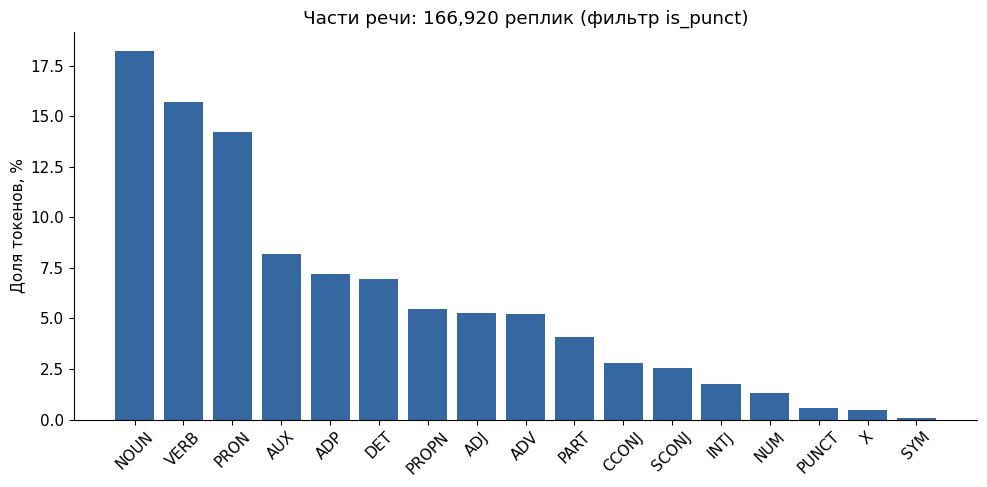

In [19]:
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([r['pos'] for r in pos_rows], [100 * r['share'] for r in pos_rows], color='#3567A0')
ax.set(ylabel='Доля токенов, %', title=f'Части речи: {processed:,} реплик (фильтр is_punct)')
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
fig.savefig(OUT / 'pos.png', dpi=150)
plt.show()
plt.close(fig)

## Сравнение условных групп

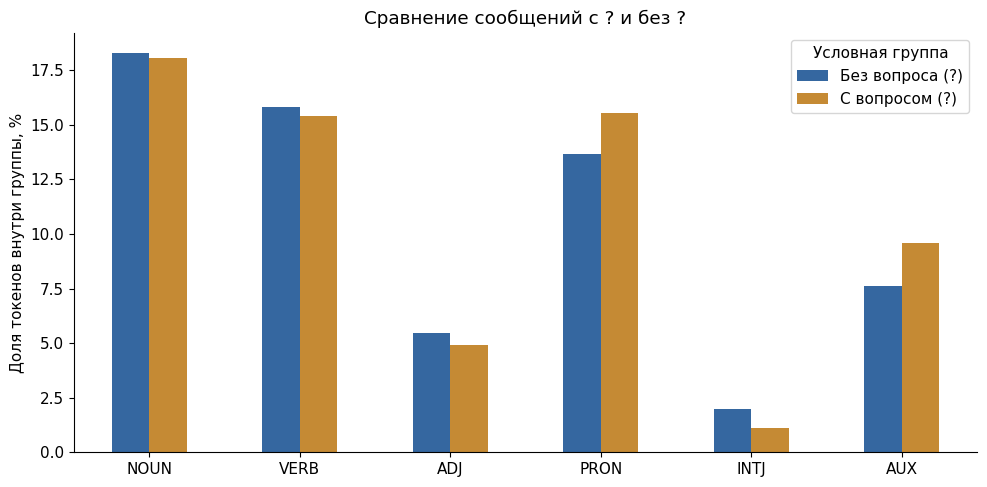

In [20]:
comp = pd.DataFrame(comparison)
focus = ['NOUN', 'VERB', 'ADJ', 'PRON', 'INTJ', 'AUX']
pivot = comp.pivot(index='pos', columns='group', values='share').reindex(focus)
ax = (pivot * 100).plot.bar(figsize=(10, 5), color=['#3567A0', '#C58A34'], rot=0)
ax.set(ylabel='Доля токенов внутри группы, %', xlabel='', title='Сравнение сообщений с ? и без ?')
ax.legend(title='Условная группа')
ax.figure.tight_layout()
ax.figure.savefig(OUT / 'pos_comparison.png', dpi=150)
plt.show()
plt.close(ax.figure)

In [21]:
display(pivot.mul(100).round(2).rename_axis('Часть речи'))

group,Без вопроса (?),С вопросом (?)
Часть речи,,
NOUN,18.31,18.04
VERB,15.83,15.39
ADJ,5.45,4.89
PRON,13.68,15.53
INTJ,2.00,1.13
AUX,7.60,9.59


## 3. Десять деревьев зависимостей

In [22]:
assert len(selected_sentences) == 10
for i, sentence in enumerate(selected_sentences, 1):
    draw_tree(sentence, i)

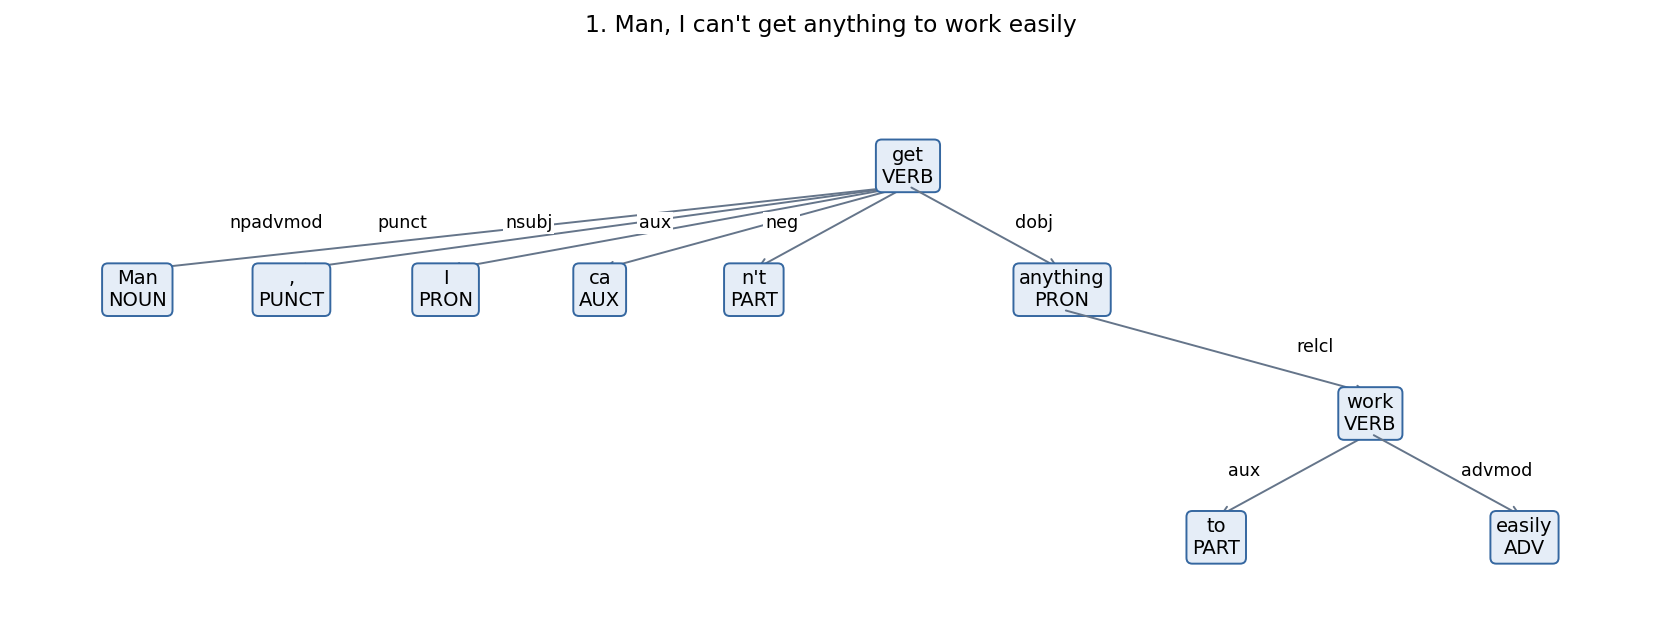

In [23]:
display(Image(filename=str(OUT / 'tree_01.png')))

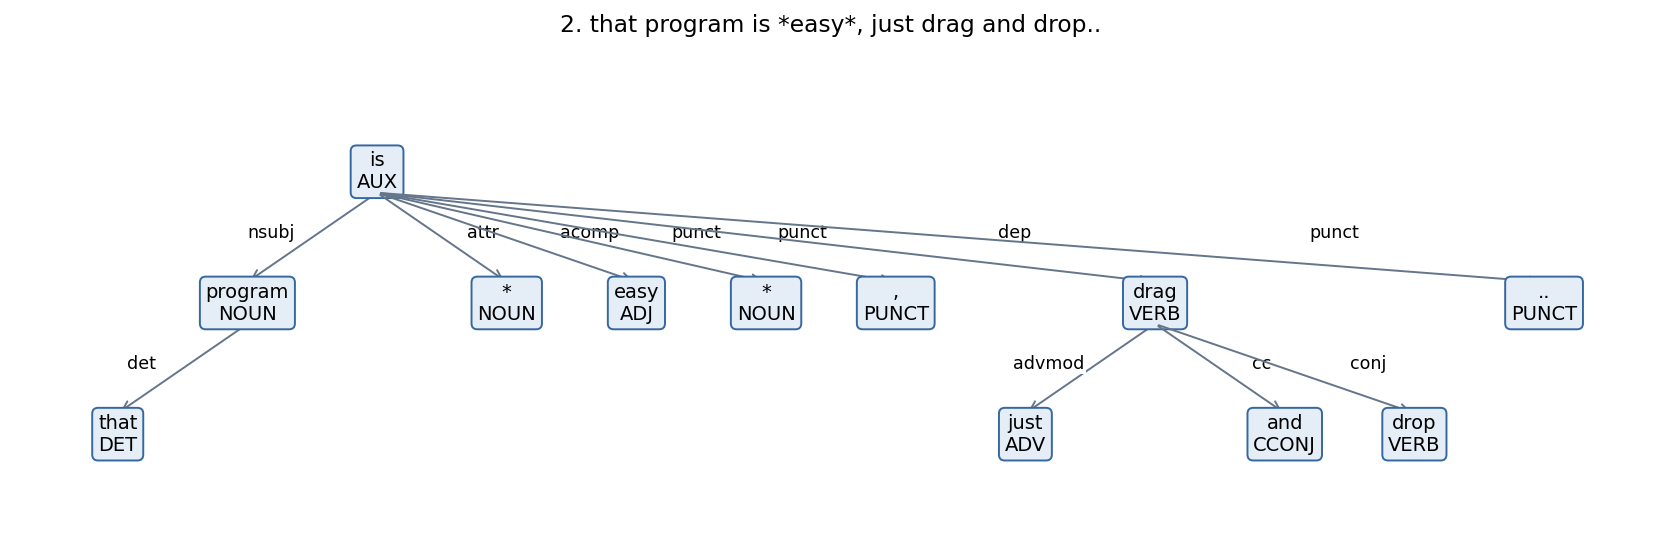

In [24]:
display(Image(filename=str(OUT / 'tree_02.png')))

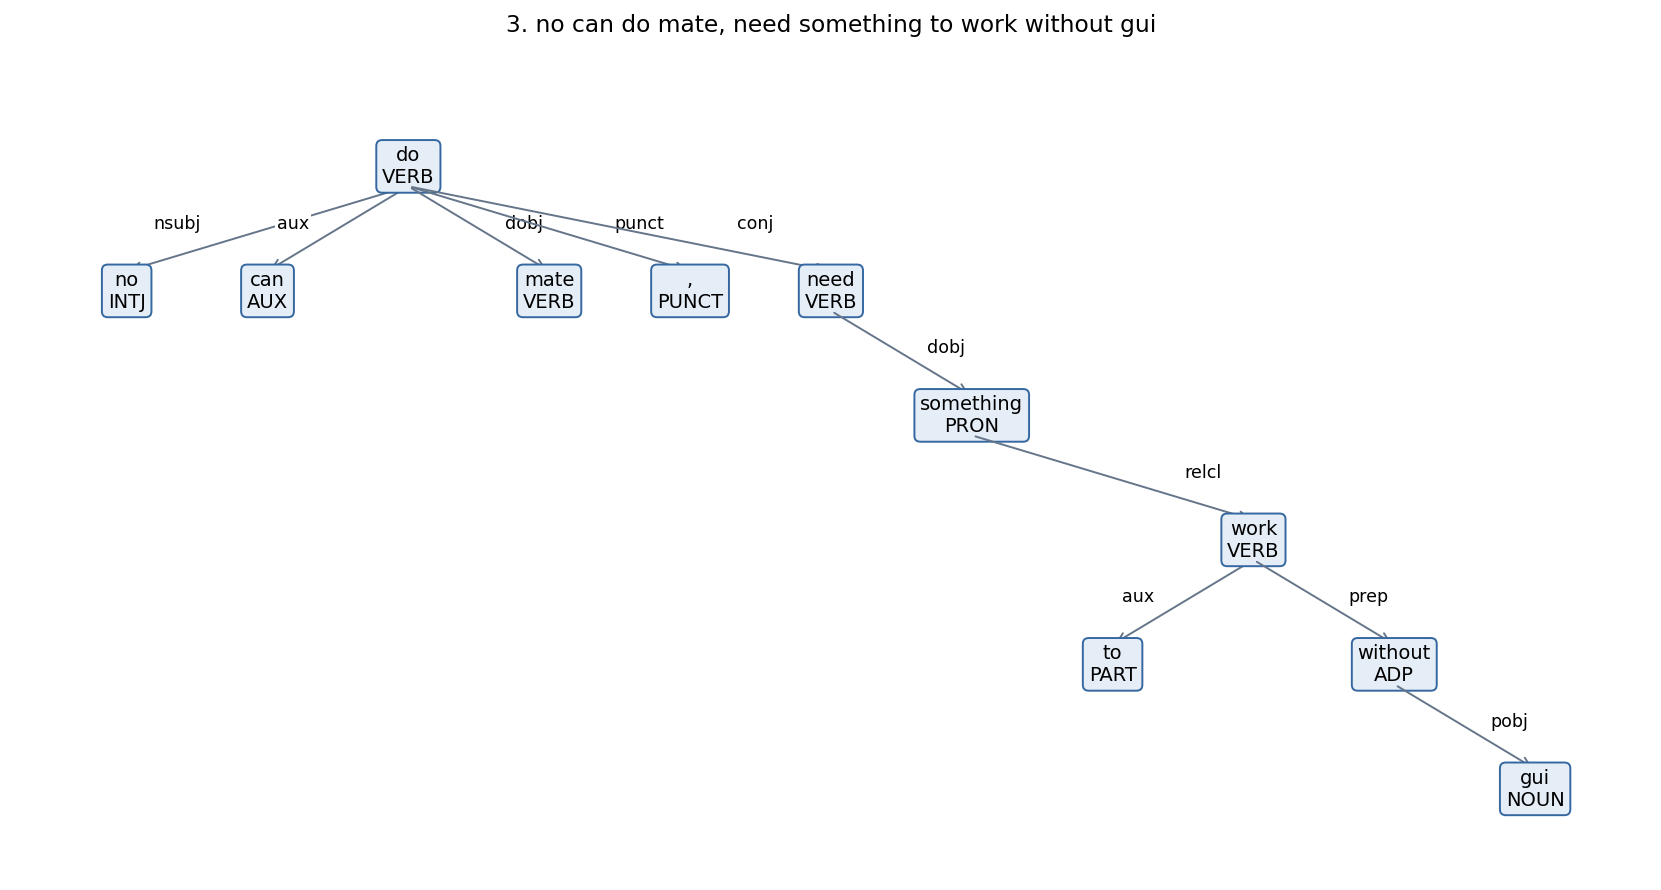

In [25]:
display(Image(filename=str(OUT / 'tree_03.png')))

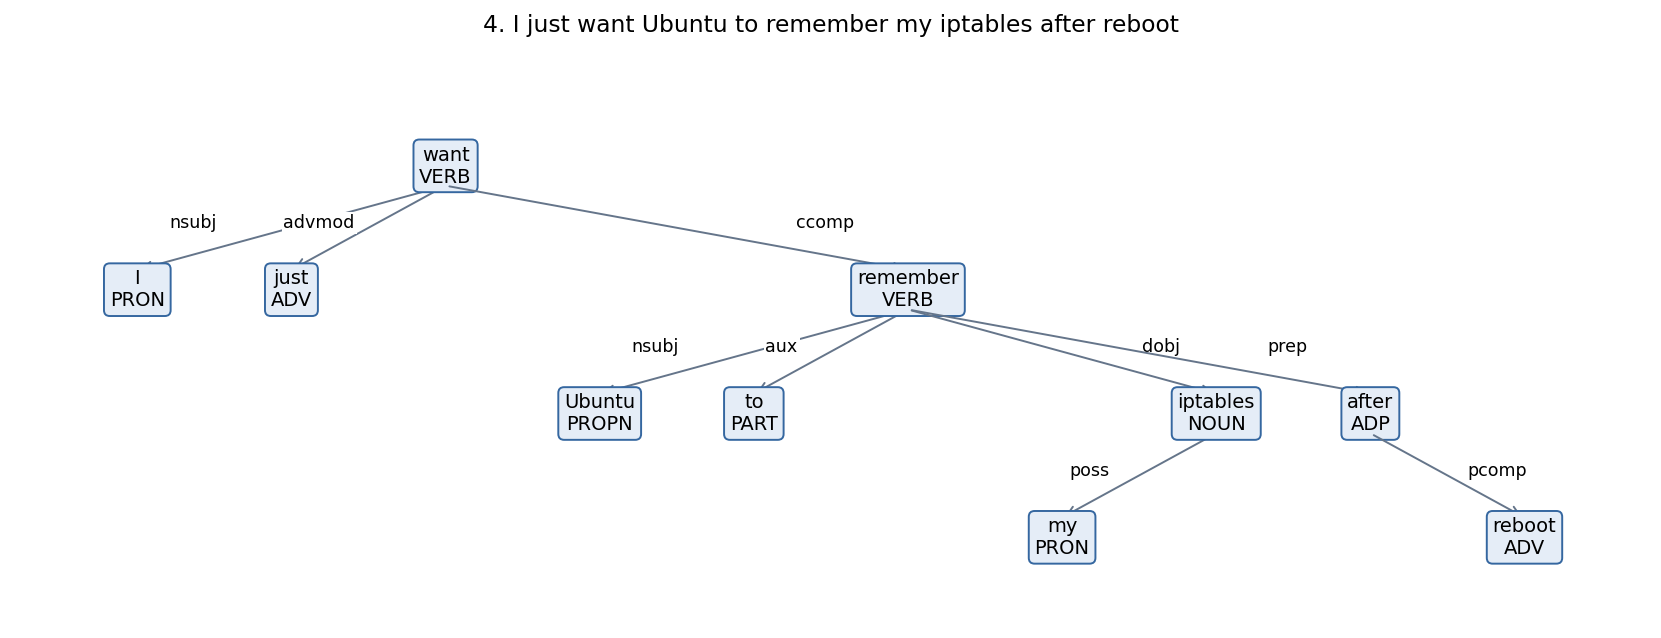

In [26]:
display(Image(filename=str(OUT / 'tree_04.png')))

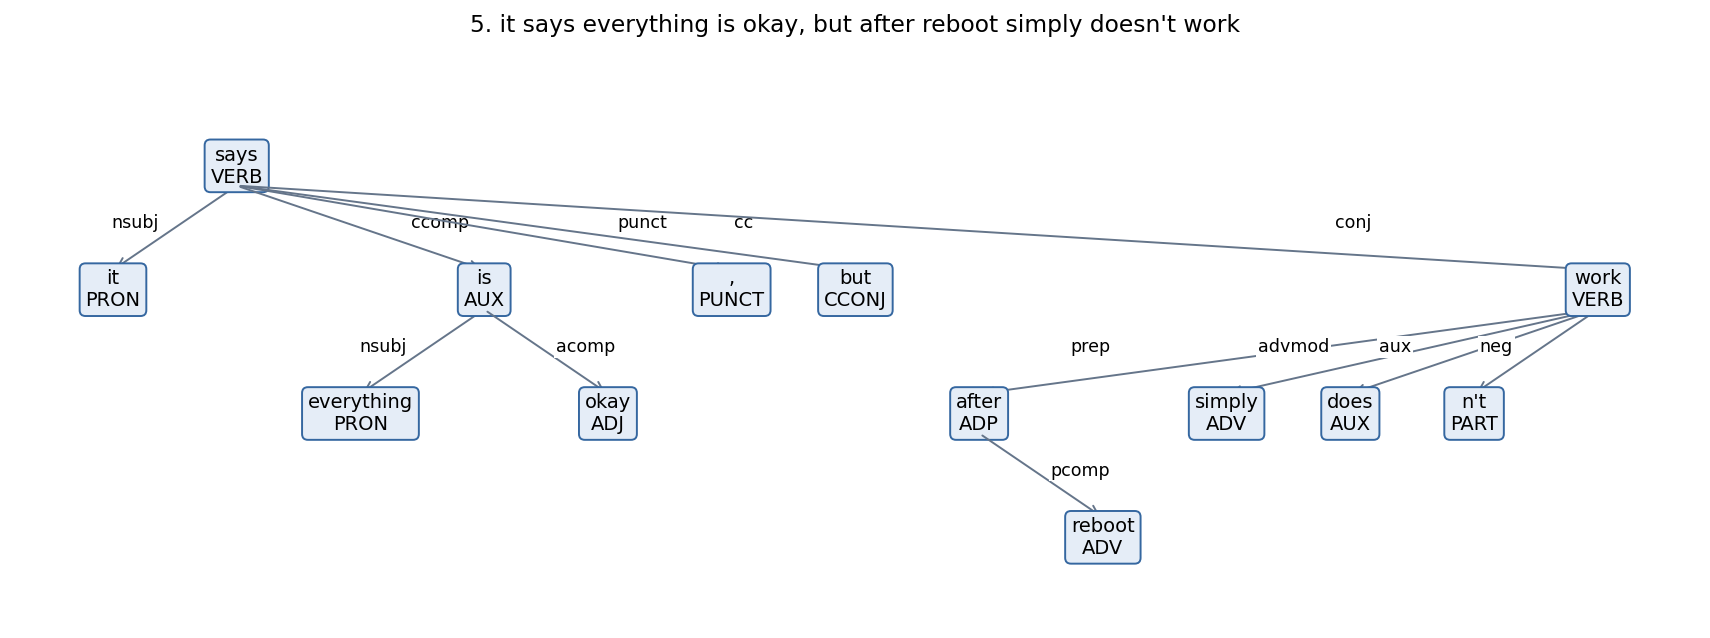

In [27]:
display(Image(filename=str(OUT / 'tree_05.png')))

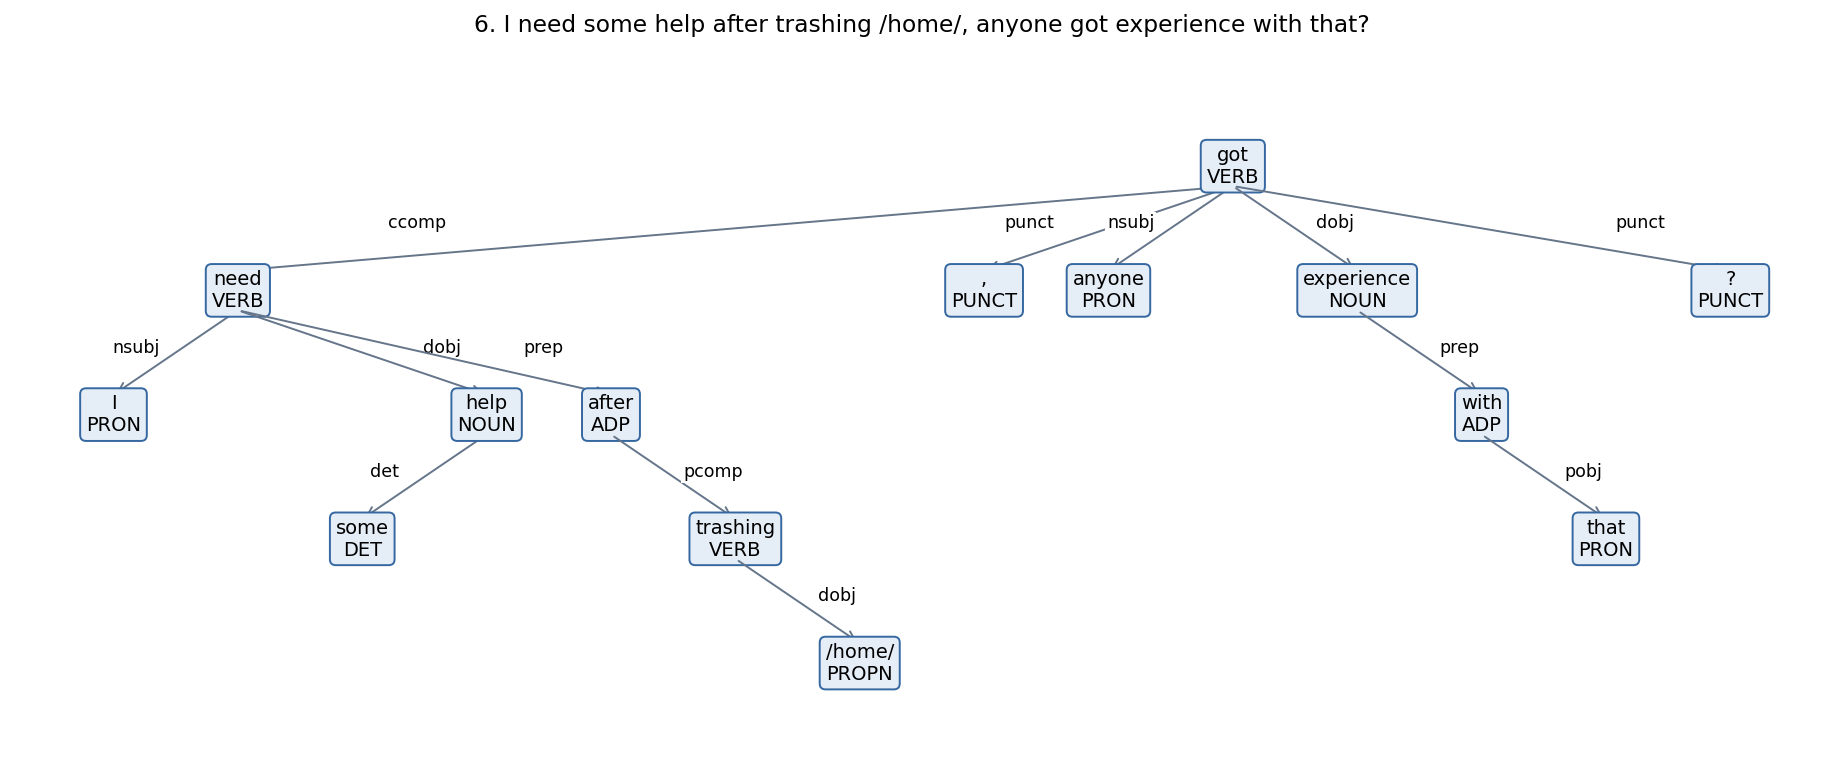

In [28]:
display(Image(filename=str(OUT / 'tree_06.png')))

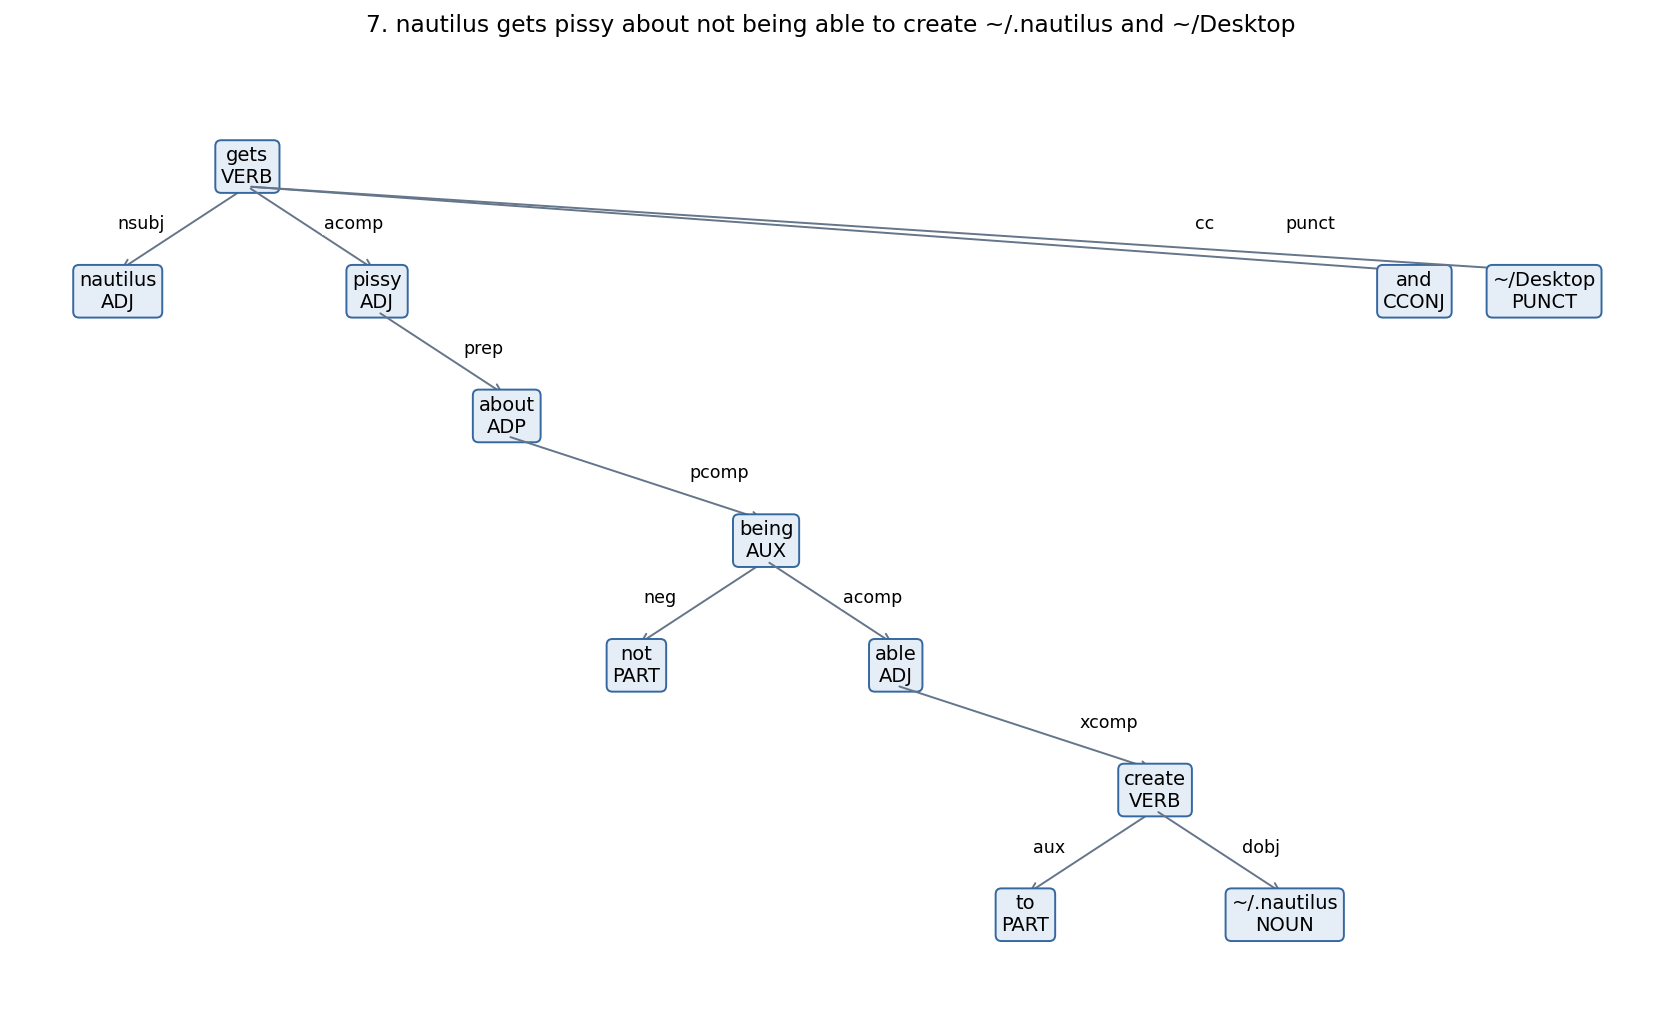

In [29]:
display(Image(filename=str(OUT / 'tree_07.png')))

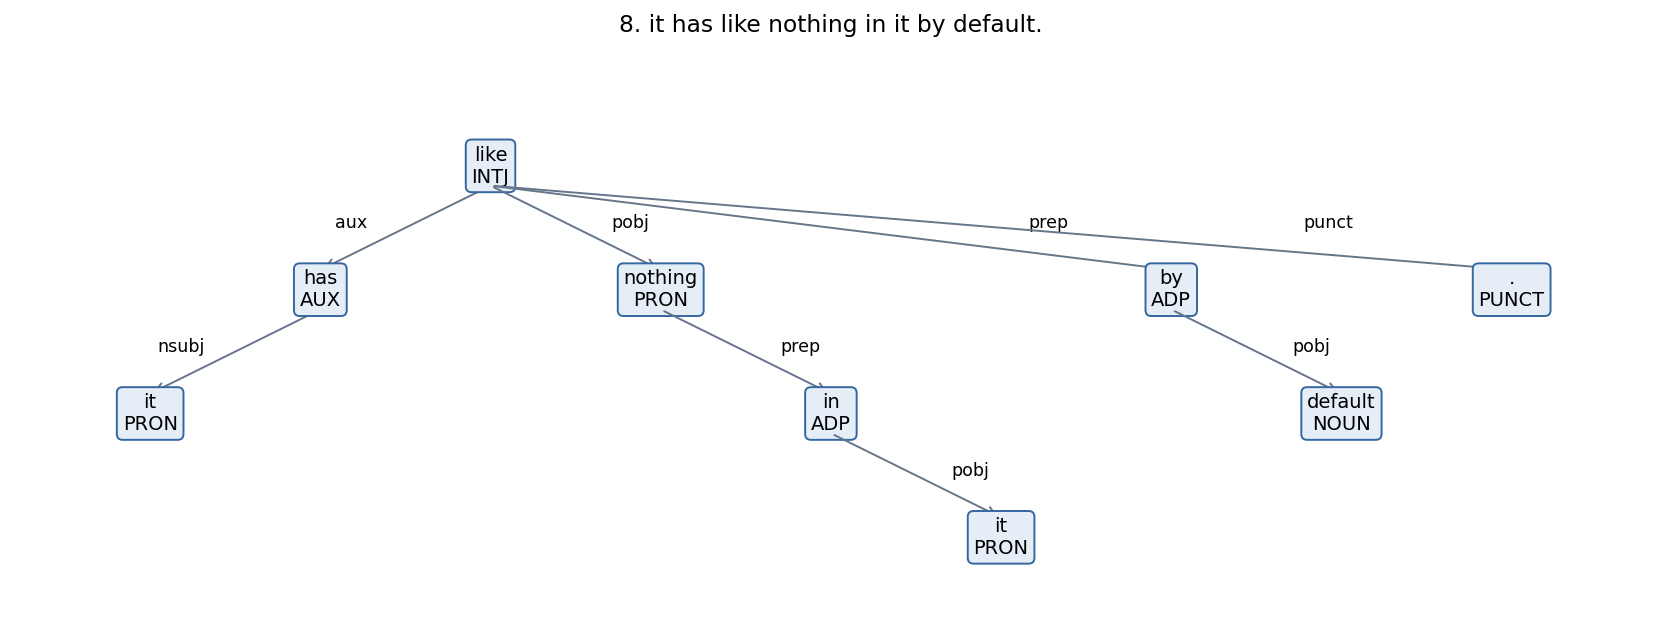

In [30]:
display(Image(filename=str(OUT / 'tree_08.png')))

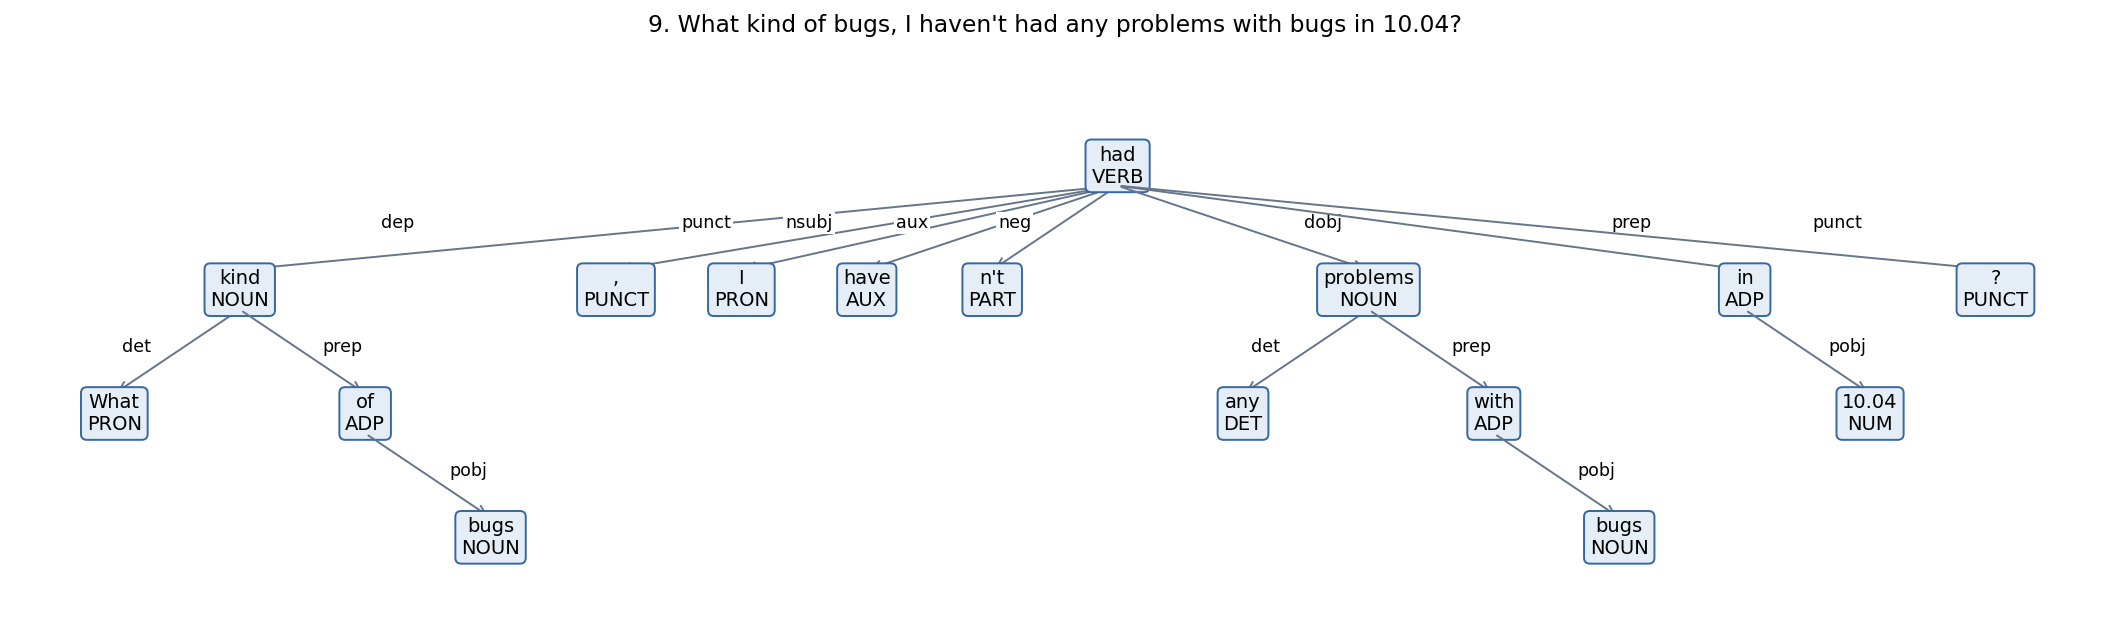

In [31]:
display(Image(filename=str(OUT / 'tree_09.png')))

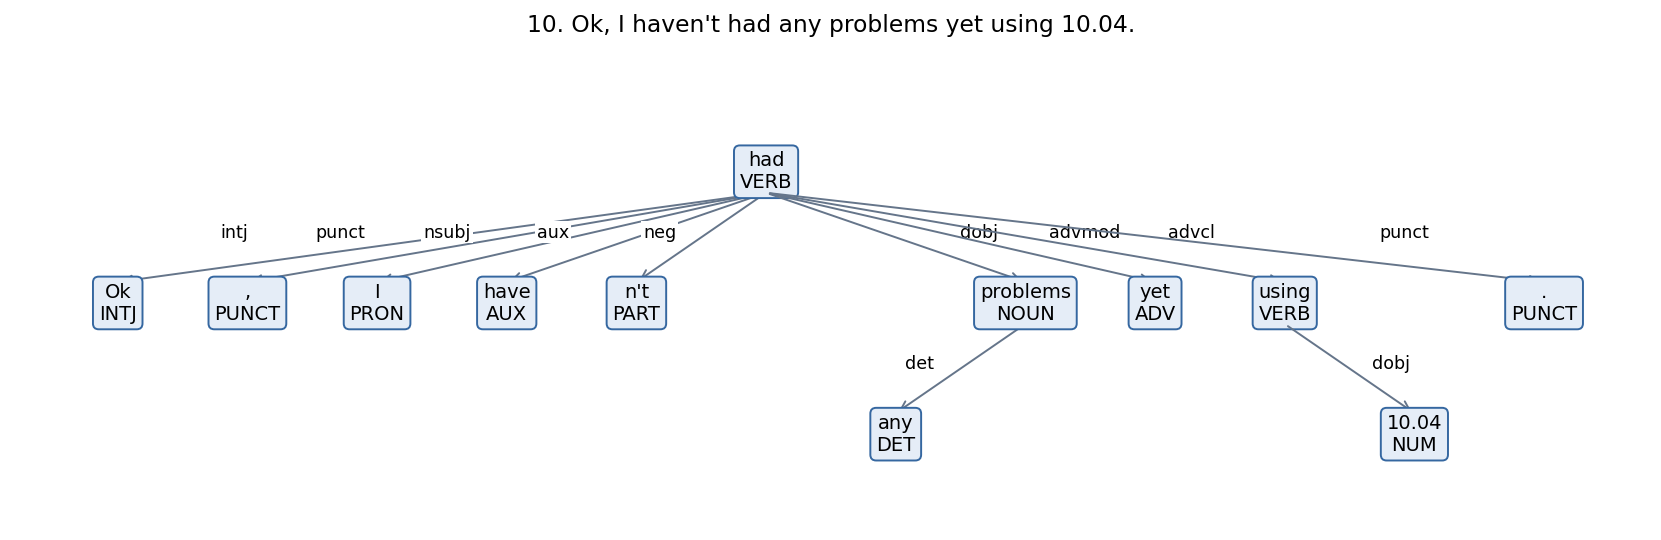

In [32]:
display(Image(filename=str(OUT / 'tree_10.png')))

## Проверка итогов

In [33]:
assert sum(group_docs.values()) == processed == len(frame)
assert sum(sum(c.values()) for c in by_group.values()) == total_tokens
assert math.isclose(sum(r['share'] for r in pos_rows), 1)
summary = dict(documents=processed, dialogues=frame.group_id.nunique(), tokens=total_tokens,
               groups=dict(group_docs), spacy_version=spacy.__version__, model=MODEL,
               model_version=nlp.meta['version'], source_sha256=hashlib.file_digest(source.open('rb'), 'sha256').hexdigest(),
               pairs=sum(pair_counts.values()), unique_pairs=len(pair_counts), passive_pairs=passive_pairs,
               pronouns=dict(pronouns), resolved=dict(resolved), trees=10,
               comparison='Группы определены только наличием ?; это не исходные классы и не разметка намерений.')
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(summary, ensure_ascii=False, indent=2), flush=True)

{
  "documents": 166920,
  "dialogues": 18506,
  "tokens": 1731856,
  "groups": {
    "Без вопроса (?)": 125559,
    "С вопросом (?)": 41361
  },
  "spacy_version": "3.8.18",
  "model": "en_core_web_sm",
  "model_version": "3.8.0",
  "source_sha256": "868ed0819ac7849a320f32fc4ac42765fbc1ed257576fdc1ad771f8bd7e266b0",
  "pairs": 168570,
  "unique_pairs": 31249,
  "passive_pairs": 7842,
  "pronouns": {
    "it": 41809,
    "they": 2560,
    "them": 2130,
    "him": 219,
    "he": 994,
    "her": 94,
    "she": 100
  },
  "resolved": {
    "it": 36643,
    "they": 1931,
    "them": 1783,
    "he": 22,
    "her": 2,
    "him": 2,
    "she": 2
  },
  "trees": 10,
  "comparison": "Группы определены только наличием ?; это не исходные классы и не разметка намерений."
}


## Пять ошибок POS-разметки
Ручная оценка реальных реплик. Это иллюстрации ошибок, не оценка точности всего корпуса.

In [34]:
display(pd.read_csv(OUT / 'pos_errors_review.csv'))

,Текст,Токен,Выдал spaCy,Ожидается,Пояснение,Диалог
0,lol mwe only one person in the sound departmen...,lol,PROPN,INTJ,"lol — реакция смеха, а не имя собственное.",60/377.tsv
1,"your drives are operating in PIO, try enabling...",ur,PROPN,DET,ur означает your и определяет существительное ...,20/7748.tsv
2,can you plz explain,plz,VERB,INTJ / маркер вежливости,"plz означает please, а не действие.",89/45.tsv
3,actually there are only 3 sections in that fil...,u,NOUN,PRON,"u означает you: субъект gave, не существительное.",89/45.tsv
4,if you can do this in a PM it would be better lol,lol,ADJ,INTJ,"lol — разговорная реакция, не признак предмета.",60/167.tsv


## 6. Примеры разрешения анафоры

In [35]:
review = pd.read_csv(OUT / 'anaphora_review.csv')
for i, row in review.iterrows():
    display(Markdown(
        f"**{i + 1}. {row['Оценка']} — {row['Местоимение']} → {row['Кандидат']}**\n\n"
        f"Контекст: {row['Контекст']}\n\n"
        f"До: {row['Исходная реплика']}\n\n"
        f"После: {row['После замены']}\n\n"
        f"{row['Комментарий']}"
    ))

**1. Правдоподобно — it → /home/**

Контекст: Had an encrypted /home/, didn't want it

До: Had an encrypted /home/, didn't want it

После: Had an encrypted /home/, didn't want /home/

it ссылается на зашифрованный /home/.

**2. Правдоподобно — it → apache**

Контекст: how do i find where is apache installed?

До: i know there is a service apache2 how do i find whre is it installed

После: i know there is a service apache2 how do i find whre is apache installed

Контекст обсуждает установку Apache; близкая связь с apache.

**3. Правдоподобно — it → /mnt**

Контекст: You should leave /mnt there for backwards compatibility in case something goes looking for it

До: You should leave /mnt there for backwards compatibility in case something goes looking for it

После: You should leave /mnt there for backwards compatibility in case something goes looking for /mnt

it ссылается на каталог /mnt.

**4. Правдоподобно — them → updates**

Контекст: so nobody knows how to clear unwanted updates out of Update Manager?

До: uncheck them

После: uncheck updates

them относится к множественному updates; число совпало.

**5. Правдоподобно — it → driver**

Контекст: I've already said to BlueEagle that the only one there is the stupid novuea 3d driver, which breaks more stuff (I can't get past splash with it installed)

До: I've already said to BlueEagle that the only one there is the stupid novuea 3d driver, which breaks more stuff (I can't get past splash with it installed)

После: I've already said to BlueEagle that the only one there is the stupid novuea 3d driver, which breaks more stuff (I can't get past splash with driver installed)

it относится к ранее упомянутому driver.

**6. Правдоподобно — it → ubuntu**

Контекст: how to reinstall ubuntu

До: how did you install it?

После: how did you install ubuntu?

Вопрос о переустановке Ubuntu; it заменено на ubuntu.

**7. Ошибка — it → save**

Контекст: i tried iptables-save to no avail

До: it says everything is okay, but after reboot simply doesn't work

После: save says everything is okay, but after reboot simply doesn't work

save — фрагмент команды iptables-save; смысловой референт по нему не установлен.

**8. Ошибка — it → question**

Контекст: I have a question

До: does it work... :)

После: does question work... :)

question не является работающим объектом; трёх реплик недостаточно для выбора референта.

**9. Частично — they → updates**

Контекст: so nobody knows how to clear unwanted updates out of Update Manager?

До: yes, that works for the moment, but they're still listed the next time Update Manager is run

После: yes, that works for the moment, but updates're still listed the next time Update Manager is run

updates выбрано по смыслу, но updates're — неграмматичный результат. Сокращения требуют отдельного восстановления.